<a href="https://colab.research.google.com/github/cursuri-inf/IPAP/blob/main/saptamana-05/curs05_demonstratii.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cursul 6. Demonstrațiile

Caietul conține demonstrațiile de la cursul 6, „Antrenarea rețelelor”, cu rezultatele salvate. Codul este cel din suportul de curs, în aceeași ordine, iar titlurile de mai jos au numerele capitolelor din suport (§2–§5).

**Cum lucrați:**

1. Deschideți caietul cu butonul „Open in Colab” de mai sus. Colab avertizează că documentul nu a fost creat de Google: caietul vine din depozitul cursului, așa că alegeți „Run anyway”.
2. Înainte să schimbați ceva: File → Save a copy in Drive; lucrați în copie.
3. Rezultatele salvate se văd și fără rulare. Ca să le obțineți din nou, rulați celulele în ordine, de sus în jos, cu Shift+Enter.
4. Celulele „Încercați acum” sunt cele de la curs: schimbați ce scrie în comentariu, rulați și comparați cu ce scrie în suport.
5. Notițele dumneavoastră: după fiecare demonstrație aveți o celulă „Notițele mele” (dublu clic pentru editare). Puteți lăsa și comentarii pe marginea din dreapta a oricărei celule: clic dreapta pe celulă, apoi „Add a comment” (sau Ctrl+Alt+M).

Caietul rulează pe procesor, în câteva minute; un GPU nu este necesar. Nu se predă și nu se notează.

## 0. Pornire

Bibliotecile, datele și funcția `pas` din laboratorul 4, neschimbată. Exemplul este cel din cursul 5: este pinguinul mascul sau femelă, după masa corporală și lungimea ciocului? Cei 333 de pinguini pentru care se știe, împărțiți 70/15/15, stratificat pe specii; intrările standardizate pe antrenare; eticheta 1 pentru mascul și 0 pentru femelă.

In [1]:
import sys
import torch
from torch import nn
from torch.optim import SGD, Adam
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset
import pandas as pd
from sklearn.model_selection import train_test_split

print("Python ", sys.version.split()[0])
print("PyTorch", torch.__version__)

Python  3.13.18
PyTorch 2.15.0+cpu


In [2]:
URL = ("https://raw.githubusercontent.com/mwaskom/"
       "seaborn-data/master/penguins.csv")
col = ["body_mass_g", "bill_length_mm"]
# 333 de pinguini la care se știe dacă sunt
# masculi sau femele
mf = pd.read_csv(URL).dropna(subset=col + ["sex"])
rest, test = train_test_split(
    mf, test_size=0.15, stratify=mf["species"],
    random_state=0)
ant, val = train_test_split(
    rest, test_size=0.15 / 0.85,
    stratify=rest["species"], random_state=0)
med, ab = ant[col].mean(), ant[col].std()

def tensori(t):   # intrările și eticheta
    z = torch.tensor(((t[col] - med) / ab).values)
    y = torch.tensor((t["sex"] == "MALE").values)
    return z.float(), y.float().reshape(-1, 1)

z_ant, y_ant = tensori(ant)
z_val, y_val = tensori(val)
print(len(ant), len(val), len(test))

233 50 50


In [3]:
# funcția pas din laboratorul 4, neschimbată
def pas(model, pierdere_f, opt, zb, yb):
    predictie = model(zb)
    pierdere = pierdere_f(predictie, yb)
    opt.zero_grad()
    pierdere.backward()
    opt.step()

def retea_noua(ascunsi=16):   # rețeaua din cursul 5
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(2, ascunsi),
                         nn.ReLU(),
                         nn.Linear(ascunsi, 1))

## D1. Bucla completă (§2)

După fiecare epocă, modelul trece o dată prin tot setul de antrenare și prin tot setul de validare, fără să învețe nimic din ele: `model.eval()` trece modelul în modul de evaluare, iar `torch.no_grad()` oprește calculul gradientului. Pierderea și acuratețea de pe ambele seturi intră într-un istoric, câte un rând pe epocă.

In [4]:
def evalueaza(model, pf, z, y):
    model.eval()            # modul de evaluare
    with torch.no_grad():   # fără gradient
        scor = model(z)
        pierdere = pf(scor, y).item()
        corect = ((scor > 0).float() == y)
    model.train()           # înapoi la antrenare
    return pierdere, corect.float().mean().item()

In [5]:
def antreneaza(model, opt, epoci, lot=32):
    pf = nn.BCEWithLogitsLoss()
    date = TensorDataset(z_ant, y_ant)
    loturi = DataLoader(date, batch_size=lot,
                        shuffle=True)
    istoric = []
    for epoca in range(epoci):
        for zb, yb in loturi:
            pas(model, pf, opt, zb, yb)
        h = evalueaza(model, pf, z_ant, y_ant)
        h += evalueaza(model, pf, z_val, y_val)
        istoric.append(h)   # 4 numere pe epocă
    return istoric

Rețeaua din cursul 5, cu SGD și rata 0,1, 300 de epoci. Fiecare rând al istoricului are: pierderea și acuratețea pe antrenare, apoi pierderea și acuratețea pe validare.

In [6]:
retea = retea_noua()
opt = SGD(retea.parameters(), lr=0.1)
ist_sgd = antreneaza(retea, opt, epoci=300)
for e in (1, 10, 100, 300):
    print(e, *[round(x, 2) for x in ist_sgd[e - 1]])

1 0.66 0.64 0.65 0.64
10 0.59 0.59 0.57 0.62
100 0.45 0.8 0.4 0.78
300 0.35 0.86 0.29 0.88


Curbele: pierderea pe antrenare și pe validare, epocă cu epocă.

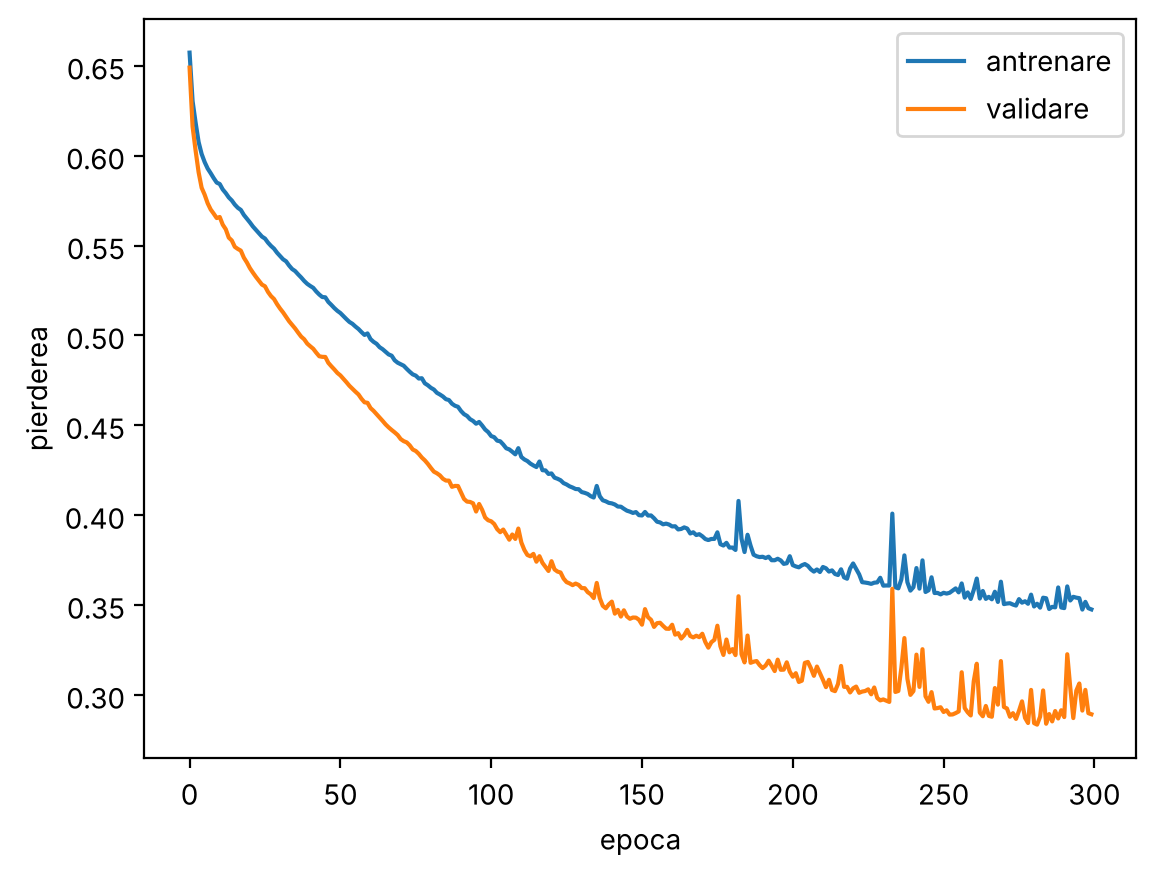

In [7]:
import matplotlib.pyplot as plt
plt.plot([h[0] for h in ist_sgd], label="antrenare")
plt.plot([h[2] for h in ist_sgd], label="validare")
plt.xlabel("epoca")
plt.ylabel("pierderea")
plt.legend()
plt.show()

### Notițele mele

…

## D2. Citirea curbelor (§3)

Patru antrenări ale aceleiași probleme: A, B și C sunt rețeaua din cursul 5 cu Adam, la trei rate; D este o rețea mai mare, cu două straturi ascunse de câte 64 de neuroni, antrenată 1000 de epoci. Pentru fiecare: pierderea pe validare după prima epocă, cea mai mică (cu epoca ei) și cea de la sfârșit.

In [8]:
curbe = {}
for nume, rata in (("A", 0.0001), ("B", 0.01),
                   ("C", 0.5)):
    r = retea_noua()
    curbe[nume] = antreneaza(
        r, Adam(r.parameters(), lr=rata), 300)

torch.manual_seed(0)
mare = nn.Sequential(nn.Linear(2, 64), nn.ReLU(),
                     nn.Linear(64, 64), nn.ReLU(),
                     nn.Linear(64, 1))
curbe["D"] = antreneaza(
    mare, Adam(mare.parameters(), lr=0.01), 1000)

for nume, ist in curbe.items():
    v = [round(h[2], 3) for h in ist]   # validare
    e = v.index(min(v))
    print(nume, v[0], v[e], e + 1, v[-1],
          round(ist[-1][0], 3))   # antrenare, final

A 0.693 0.567 296 0.567 0.586
B 0.623 0.264 273 0.296 0.298
C 0.5 0.378 11 0.567 0.529
D 0.542 0.262 29 0.605 0.137


Neuronii ReLU inactivi (cursul 5, §5): neuronii ascunși care dau 0 pentru toți pinguinii de antrenare nu mai primesc gradient, deci nu mai învață. Câți sunt după 300 de epoci cu Adam, la patru rate? Ultima coloană este acuratețea pe validare.

In [9]:
def inactivi(model):   # neuronii mereu 0
    with torch.no_grad():
        h = torch.relu(model[0](z_ant))
    return int((h == 0).all(dim=0).sum())

for rata in (0.01, 0.1, 0.5, 1.0):
    r = retea_noua()
    opt = Adam(r.parameters(), lr=rata)
    ist = antreneaza(r, opt, 300)
    print(rata, inactivi(r), round(ist[-1][3], 2))

0.01 2 0.84


0.1 6 0.9


0.5 13 0.64


1.0 16 0.48


Lotul (cursul 4, §5.3): câți pinguini vede un pas. Aceeași rețea și același SGD cu rata 0,1, cu trei loturi: 4 pinguini, 32 (ca până acum) și tot setul de antrenare. Pentru fiecare: pașii pe epocă, epoca la care pierderea pe validare coboară prima dată sub 0,35, pierderea cea mai mică pe validare și cea de la sfârșit.

In [10]:
import math

def prima_sub(ist, prag=0.35):
    return next((e + 1 for e, h in enumerate(ist)
                 if h[2] <= prag), None)

def minim(ist):   # pierderea minimă pe validare
    return round(min(h[2] for h in ist), 3)

loturi_ist = {}
for lot in (4, 32, len(z_ant)):
    r = retea_noua()
    opt = SGD(r.parameters(), lr=0.1)
    ist = antreneaza(r, opt, 300, lot=lot)
    loturi_ist[lot] = ist
    pasi = math.ceil(len(z_ant) / lot)
    print(lot, pasi, prima_sub(ist), minim(ist),
          round(ist[-1][2], 3))

4 59 23 0.267 0.434


32 8 138 0.283 0.289


233 1 None 0.5 0.5


### Notițele mele

…

## D3. Optimizatorii (§4)

Întâi scara intrărilor (cursul 4, §5.2). Aceeași rețea, pe aceleași date, dar cu masa în grame și ciocul în milimetri, fără standardizare. Pierderea la pornire și gradientul mediu al primului strat pe fiecare intrare (masa, ciocul), întâi pe intrările standardizate, apoi în grame și milimetri; apoi cele două antrenări pe grame și milimetri, cu SGD 0,1 și cu Adam 0,01. La sfârșit, intrările standardizate se pun la loc.

In [11]:
# aceleași date, în grame și milimetri
def brute(t):
    return torch.tensor(t[col].values).float()

def la_pornire():   # pierderea și gradientul
    r = retea_noua()
    p = nn.BCEWithLogitsLoss()(r(z_ant), y_ant)
    p.backward()
    g = r[0].weight.grad.abs().mean(dim=0)
    print(round(p.item(), 2), g.numpy().round(4))

la_pornire()           # intrările standardizate
std = (z_ant, z_val)   # le păstrăm
z_ant, z_val = brute(ant), brute(val)
la_pornire()           # grame și milimetri

for nume, rata in (("SGD", 0.1), ("Adam", 0.01)):
    r = retea_noua()
    O = SGD if nume == "SGD" else Adam
    ist = antreneaza(r, O(r.parameters(), lr=rata),
                     300)
    print(nume, prima_sub(ist), minim(ist))

z_ant, z_val = std   # înapoi la standardizate

0.69 [0.0072 0.0091]
59.81 [38.6412  0.4187]


SGD None 0.693


Adam None 0.599


Acum, pe intrările standardizate, aceeași rețea, aceeași buclă, trei optimizatori. Codul se schimbă într-un singur rând, cel care creează optimizatorul. Pentru fiecare: epoca la care pierderea pe validare coboară prima dată sub 0,35 și pierderea cea mai mică pe validare.

In [12]:
optimizatori = {
    "SGD": lambda p: SGD(p, lr=0.1),
    "moment": lambda p: SGD(p, lr=0.1,
                            momentum=0.9),
    "Adam": lambda p: Adam(p, lr=0.01)}
istorice = {}
for nume, f in optimizatori.items():
    r = retea_noua()
    ist = antreneaza(r, f(r.parameters()), 300)
    istorice[nume] = ist
    print(nume, prima_sub(ist), minim(ist))

SGD 138 0.283


moment 20 0.275


Adam 45 0.264


Rata bună depinde de optimizator. Adam, la cinci rate: epoca la care validarea coboară sub 0,35, pierderea cea mai mică pe validare și neuronii inactivi la sfârșit.

In [13]:
for rata in (0.0001, 0.001, 0.01, 0.1, 0.5):
    r = retea_noua()
    opt = Adam(r.parameters(), lr=rata)
    ist = antreneaza(r, opt, 300)
    print(rata, prima_sub(ist), minim(ist),
          inactivi(r))

0.0001 None 0.567 2


0.001 None 0.394 2


0.01 45 0.264 2


0.1 9 0.3 6


0.5 None 0.378 13


### Încercați acum

În perechi: fiecare pereche primește un optimizator și o rată. Prevedeți întâi: coboară validarea sub 0,35 mai repede sau mai încet decât cu Adam la 0,01? Apoi rulați și notați epoca și pierderea cea mai mică.

In [14]:
# "sgd", "moment" sau "adam"; rata: schimbați
OPTIMIZATOR = "moment"
RATA = 0.05

r = retea_noua()
if OPTIMIZATOR == "adam":
    opt = Adam(r.parameters(), lr=RATA)
else:
    m = 0.9 if OPTIMIZATOR == "moment" else 0
    opt = SGD(r.parameters(), lr=RATA, momentum=m)
ist = antreneaza(r, opt, 300)
print(prima_sub(ist), minim(ist))

33 0.27


### Notițele mele

…

## D4. Scriptul de antrenare (§5)

Bucla completă se mută într-un fișier, `train.py`. Celula de mai jos îl scrie în folderul caietului (`%%writefile`); hiperparametrii vin din argumente, iar sămânța fixată face ca aceeași comandă să dea aceleași cifre.

In [15]:
%%writefile train.py
"""Bucla completă pentru întrebarea „mascul sau
femelă?” (cursul 6, §5). Exemplu de rulare:
python train.py --opt adam --rata 0.01"""
import argparse, os
import pandas as pd
import torch
from torch import nn
from torch.optim import SGD, Adam
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset
from sklearn.model_selection import train_test_split

p = argparse.ArgumentParser()
p.add_argument("--opt", default="sgd",
               choices=["sgd", "moment", "adam"])
p.add_argument("--rata", type=float, default=0.1)
p.add_argument("--epoci", type=int, default=300)
p.add_argument("--lot", type=int, default=32)
p.add_argument("--ascunsi", type=int, default=16)
p.add_argument("--samanta", type=int, default=0)
a = p.parse_args()

# datele, ca în caietul demonstrațiilor
URL = ("https://raw.githubusercontent.com/mwaskom/"
       "seaborn-data/master/penguins.csv")
sursa = "penguins.csv"
if not os.path.exists(sursa):
    sursa = URL
col = ["body_mass_g", "bill_length_mm"]
mf = pd.read_csv(sursa).dropna(subset=col + ["sex"])
rest, test = train_test_split(
    mf, test_size=0.15, stratify=mf["species"],
    random_state=0)
ant, val = train_test_split(
    rest, test_size=0.15 / 0.85,
    stratify=rest["species"], random_state=0)
med, ab = ant[col].mean(), ant[col].std()

def tensori(t):
    z = torch.tensor(((t[col] - med) / ab).values)
    y = torch.tensor((t["sex"] == "MALE").values)
    return z.float(), y.float().reshape(-1, 1)

z_ant, y_ant = tensori(ant)
z_val, y_val = tensori(val)

def evalueaza(model, pf, z, y):
    model.eval()
    with torch.no_grad():
        scor = model(z)
        pierdere = pf(scor, y).item()
        corect = ((scor > 0).float() == y)
    model.train()
    return pierdere, corect.float().mean().item()

# modelul și optimizatorul, după argumente
torch.manual_seed(a.samanta)
model = nn.Sequential(nn.Linear(2, a.ascunsi),
                      nn.ReLU(),
                      nn.Linear(a.ascunsi, 1))
if a.opt == "adam":
    opt = Adam(model.parameters(), lr=a.rata)
else:
    moment = 0.9 if a.opt == "moment" else 0
    opt = SGD(model.parameters(), lr=a.rata,
              momentum=moment)
pf = nn.BCEWithLogitsLoss()
loturi = DataLoader(TensorDataset(z_ant, y_ant),
                    batch_size=a.lot, shuffle=True)

# bucla completă: antrenare, apoi validare
istoric = []
for epoca in range(1, a.epoci + 1):
    for zb, yb in loturi:
        pierdere = pf(model(zb), yb)
        opt.zero_grad()
        pierdere.backward()
        opt.step()
    h = evalueaza(model, pf, z_ant, y_ant)
    h += evalueaza(model, pf, z_val, y_val)
    istoric.append(h)
    if epoca % max(1, a.epoci // 5) == 0:
        print(f"epoca {epoca:4}: pierderea"
              f" {h[0]:.3f} / {h[2]:.3f}"
              f" | validare {h[3]:.0%}")

e = min(range(a.epoci), key=lambda i: istoric[i][2])
print(f"minimul pe validare: {istoric[e][2]:.3f},"
      f" la epoca {e + 1} ({istoric[e][3]:.0%})")

Writing train.py


Rulăm scriptul din caiet, cu `!`, ca dintr-un terminal: Adam, rata 0,01, 100 de epoci.

In [16]:
!python train.py --opt adam --rata 0.01 --epoci 100

epoca   20: pierderea 0.496 / 0.455 | validare 76%


epoca   40: pierderea 0.411 / 0.363 | validare 90%


epoca   60: pierderea 0.361 / 0.323 | validare 90%


epoca   80: pierderea 0.340 / 0.312 | validare 86%


epoca  100: pierderea 0.328 / 0.296 | validare 90%
minimul pe validare: 0.292, la epoca 97 (88%)


Aceeași comandă, încă o dată: aceleași cifre, până la ultima zecimală.

In [17]:
!python train.py --opt adam --rata 0.01 --epoci 100

epoca   20: pierderea 0.496 / 0.455 | validare 76%


epoca   40: pierderea 0.411 / 0.363 | validare 90%


epoca   60: pierderea 0.361 / 0.323 | validare 90%


epoca   80: pierderea 0.340 / 0.312 | validare 86%


epoca  100: pierderea 0.328 / 0.296 | validare 90%
minimul pe validare: 0.292, la epoca 97 (88%)


Altă rată se încearcă din comandă, fără să schimbăm codul:

In [18]:
!python train.py --opt adam --rata 0.1 --epoci 100

epoca   20: pierderea 0.351 / 0.313 | validare 90%


epoca   40: pierderea 0.342 / 0.371 | validare 84%


epoca   60: pierderea 0.336 / 0.332 | validare 88%


epoca   80: pierderea 0.314 / 0.379 | validare 84%


epoca  100: pierderea 0.292 / 0.348 | validare 88%
minimul pe validare: 0.300, la epoca 30 (88%)


Sămânța fixează pornirea și amestecarea loturilor. Cu altă sămânță, aceeași configurație dă alte cifre. Trei configurații, fiecare cu cinci semințe (0–4), 100 de epoci: cea mai mică și cea mai mare dintre pierderile minime pe validare.

In [19]:
def retea_samanta(s):   # altă sămânță, alt start
    torch.manual_seed(s)
    return nn.Sequential(nn.Linear(2, 16),
                         nn.ReLU(),
                         nn.Linear(16, 1))

config = {
    "Adam 0.01": lambda p: Adam(p, lr=0.01),
    "moment 0.1": lambda p: SGD(p, lr=0.1,
                                momentum=0.9),
    "SGD 0.1": lambda p: SGD(p, lr=0.1)}
for nume, f in config.items():
    m = []
    for s in range(5):   # cinci semințe
        r = retea_samanta(s)
        ist = antreneaza(r, f(r.parameters()), 100)
        m.append(minim(ist))
    print(nume, min(m), max(m))

Adam 0.01 0.287 0.309


moment 0.1 0.275 0.304


SGD 0.1 0.384 0.451


### Notițele mele

…

## Mai departe

La laboratorul 6 completați validarea din bucla completă, citiți curbele, alegeți optimizatorul și rata pe validare și rulați `train.py` cu alegerea dumneavoastră, de două ori, cu aceleași cifre. La cursul 7: date tabulare, supraînvățarea și cum o împiedicăm (regularizarea), recapitularea pentru Testul 1.